
---

Headers for liscence and copyright 

---


# Segmentation quality control with nnQC

nnQC is a method to grade a segmentation mask without an expert mask reference . it redraws the mask it thinks is right ( pGT) and reports the overlap, Dice(candidate,pGT). Goal Dice(candidate,pGT) ≈ Dice(candidate,GT)

This tutorial uses the MSD Spleen dataset [3] and has three parts:

1. Run the released nnQC spleen model on one patient with `nnqc.check`.
2. Train a small version of both nnQC stages (autoencoder, then diffusion UNet) with nnQC's own training functions.
3. Evaluate the small model and show the results.

All nnQC code is used unchanged from the published repository (https://github.com/robustml-eurecom/nnQC, commit `04fa2eb`). 

[1] V. Marcianò et al., "Diffusion-Based Quality Control of Medical Image Segmentations across Organs", IEEE Transactions on Medical Imaging, 2026. https://doi.org/10.1109/TMI.2026.3714697

[2] M. U. Khattak et al., "UniMed-CLIP: Towards a Unified Image-Text Pretraining Paradigm for Diverse Medical Imaging Modalities", arXiv:2412.10372, 2024.

[3] M. Antonelli et al., "The Medical Segmentation Decathlon", Nature Communications, 2022.


---

## Setup environment
Here we install the packages nnQC's code imports. The next cell then downloads nnQC's source code, unchanged, and puts it on the Python path.

nnQC's image expert needs the UniMed-CLIP *fork* of `open_clip`. The upstream `open-clip-torch` package lacks functions that nnQC calls, such as `get_mean_std`.

In [1]:
!python -c "import monai" || pip install -q "monai-weekly[nibabel, tqdm]"
!python -c "import matplotlib" || pip install -q matplotlib
!python -c "from open_clip import get_mean_std" || pip install -q https://github.com/mbzuai-oryx/UniMed-CLIP/archive/main.zip
!python -c "import cv2, transformers" || pip install -q opencv-python-headless transformers
!python -c "import lpips, scipy, tensorboard, huggingface_hub" || pip install -q lpips scipy tensorboard huggingface_hub
%matplotlib inline

<project_dir>\.venv\Lib\site-packages\timm\models\layers\__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)



---

## Setup imports

`download_and_extract` fetches nnQC's source code at commit `04fa2eb` into `./nnqc_src` (only first time).

In [2]:
import contextlib
import glob
import io
import os
import sys

import matplotlib.pyplot as plt
import nibabel as nib
import numpy as np
import torch
import transformers
from huggingface_hub import hf_hub_download, snapshot_download
from monai.apps import DecathlonDataset, download_and_extract
from monai.config import print_config
from monai.utils import set_determinism
from scipy.stats import pearsonr, spearmanr
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

NNQC_COMMIT = "04fa2ebf51f5a92e648fd97045ff4116cf3bfc5f"
download_and_extract(
    f"https://github.com/robustml-eurecom/nnQC/archive/{NNQC_COMMIT}.zip",
    filepath=f"nnqc_src/nnQC-{NNQC_COMMIT}.zip",
    output_dir="nnqc_src",
)
sys.path.insert(0, os.path.abspath(f"nnqc_src/nnQC-{NNQC_COMMIT}"))
import nnqc  # noqa: E402
from nnqc.corruptions import corrupt_ohe_masks_v2, scaled_config  # noqa: E402
from nnqc.metrics import DiceMetric  # noqa: E402

transformers.logging.set_verbosity_error()  # no BERT "LOAD REPORT" each time nnQC builds UniMedCLIP
transformers.logging.disable_progress_bar()  # no "Loading weights" bar either
print(f"nnqc {nnqc.__version__} imported from {os.path.relpath(os.path.dirname(nnqc.__file__))}")
print_config()

<project_dir>\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2026-11-09 12:16:40,351 - INFO - File exists: nnqc_src\nnQC-04fa2ebf51f5a92e648fd97045ff4116cf3bfc5f.zip, skipped downloading.
2026-11-09 12:16:40,352 - INFO - Non-empty folder exists in nnqc_src\nnQC-04fa2ebf51f5a92e648fd97045ff4116cf3bfc5f, skipped extracting.
nnqc 0.1.0 imported from nnqc_src\nnQC-04fa2ebf51f5a92e648fd97045ff4116cf3bfc5f\nnqc
MONAI version: 1.6.1
Numpy version: 2.5.4
Pytorch version: 2.15.0+cu134
MONAI flags: HAS_EXT=False, USE_COMPILED=False, USE_META_DICT=False
MONAI rev id: 7af492176792f9069b8f1253d099abd05c5e769d
MONAI __file__: <project_dir>\.venv\Lib\site-packages\monai\__init__.py

Optional dependencies:
Pytorch Ignite version: NOT INSTALLED or UNKNOWN VERSION.
ITK version: NOT INSTALLED or UNKNOWN VERSION.
Nibabel version: 5.4.2
scikit-image version: 0.26.0
scipy version: 1.18.1
Pillow version: 13.0.0
Tensorboard version: 2.21.0
gdown version: NOT INSTALLED or UNKNOWN VERSION.
TorchVision version: 0.29.2+cu134
tqdm version: 4.70.1
lmdb version: NOT INSTALLED

<project_dir>\.venv\Lib\site-packages\monai\apps\utils.py:243: UserWarning: No hash value provided for nnqc_src\nnQC-04fa2ebf51f5a92e648fd97045ff4116cf3bfc5f.zip; file integrity is NOT verified.
  if not check_hash(filepath, hash_val, hash_type):



## Setup data directory

You can specify a directory with the `MONAI_DATA_DIRECTORY` environment variable. This allows you to save results and reuse downloads. If not specified, `./data` is used.

In [3]:
directory = os.environ.get("MONAI_DATA_DIRECTORY")
root_dir = "./data" if directory is None else directory
os.makedirs(root_dir, exist_ok=True)
print(root_dir)

./data



## Set deterministic training for reproducibility

In [4]:
set_determinism(seed=0)


---

## Download MSD Spleen and take nnQC's validation split

nnQC's MSD data loader (`prepare_msd_dataloader` in `nnqc/utils.py`) splits the 41 labelled spleen CT scans with MONAI's `DecathlonDataset`,(seed 0 and  20% for validation). 

The cell below asks `DecathlonDataset` for that same validation split. The first time, it also downloads the dataset (1.5 GB).

In [5]:
val_ds = DecathlonDataset(
    root_dir=root_dir,
    task="Task09_Spleen",
    section="validation",
    seed=0,
    download=True,
    cache_rate=0.0,
    num_workers=0,
)
val_files = val_ds.data
print(f"{len(val_files)} validation patients:", [os.path.basename(f["image"]) for f in val_files])

2026-11-09 12:16:44,952 - INFO - Verified 'Task09_Spleen.tar', md5: 410d4a301da4e5b2f6f86ec3ddba524e.
2026-11-09 12:16:44,953 - INFO - File exists: data\Task09_Spleen.tar, skipped downloading.
2026-11-09 12:16:44,955 - INFO - Non-empty folder exists in data\Task09_Spleen, skipped extracting.
8 validation patients: ['spleen_32.nii.gz', 'spleen_61.nii.gz', 'spleen_28.nii.gz', 'spleen_3.nii.gz', 'spleen_46.nii.gz', 'spleen_59.nii.gz', 'spleen_12.nii.gz', 'spleen_25.nii.gz']



---

## Part 1: run the released nnQC model on one patient



In [6]:
weights_dir = "./weights"
hf_dir = snapshot_download(
    "sanbast/nnQC", allow_patterns="weights_spleen/*", local_dir=os.path.join(weights_dir, "nnqc_hf")
)
model_dir = os.path.join(hf_dir, "weights_spleen")
print("released spleen checkpoints:", sorted(os.listdir(model_dir)))

released spleen checkpoints: ['autoencoder.pt', 'diffusion_unet.pt', 'embed.pt', 'scale_factor.txt', 'xa.pt']



### Prepare the UniMedCLIP backbone

The published UniMedCLIP file (2.35 GB) is a full training checkpoint that also stores numpy values. we strip to only model weight. 



In [7]:
clip_file = hf_hub_download("UzairK/unimed-clip-vit-b16", "unimed-clip-vit-b16.pt", local_dir=weights_dir)
clip_weights = os.path.join(weights_dir, "unimed_clip_vit_b16.pt")
if not os.path.isfile(clip_weights):
    checkpoint = torch.load(clip_file, map_location="cpu", weights_only=False)  # trusted source, loaded once
    print("entries in the published file:", list(checkpoint))
    torch.save(checkpoint.get("state_dict", checkpoint), clip_weights)  # keep only the model weights
    del checkpoint
os.environ["NNQC_CLIP_PATH"] = clip_weights
print(f"published file: {os.path.getsize(clip_file) / 1e9:.2f} GB")
print(f"weights only:   {os.path.getsize(clip_weights) / 1e9:.2f} GB")

published file: 2.35 GB
weights only:   0.78 GB



### Two candidate masks for the same patient

We give nnQC two candidates for the first validation patient:

1. the expert mask from MSD, which should get a high score;
2. the same mask damaged with nnQC's own corruption function, `corrupt_ohe_masks_v2`, at its default setting=1. nnQC works on 2D axial slices, so the function is applied to every slice of the volume.

Because we have the expert mask here, we can also print the true Dice(GT,pGT) of the damaged candidate. 

In [8]:
case = val_files[0]
work_dir = os.path.join(root_dir, "nnqc_work")
os.makedirs(work_dir, exist_ok=True)

label_nii = nib.load(case["label"])
expert = np.asarray(label_nii.dataobj).astype(np.float32)  # [H, W, slices]
slices = torch.from_numpy(expert).permute(2, 0, 1).unsqueeze(1)  # [slices, 1, H, W], one 2D mask per axial slice
damaged = corrupt_ohe_masks_v2(slices, corruption_prob=1.0)  # nnQC's default corruption
damaged = damaged[:, 0].permute(1, 2, 0).numpy()  # back to [H, W, slices]
damaged_path = os.path.join(work_dir, "candidate_damaged.nii.gz")
nib.save(nib.Nifti1Image(damaged, label_nii.affine), damaged_path)

dice = DiceMetric()  # nnQC's Dice, the one nnqc.check uses for its score
print("patient:", os.path.basename(case["image"]))
print(f"true Dice of the damaged mask against the expert mask: {dice(damaged, expert):.3f}")

patient: spleen_32.nii.gz
true Dice of the damaged mask against the expert mask: 0.904


### Ask nnQC to score both candidates

`nnqc.check` takes a scan and a candidate mask and:

1. preprocesses : RAS orientation, crop to the slices that contain the candidate, crop to the body, resize to 256 x 256, and scale the CT intensities from the [-57, 164] HU window;
2. builds the condition for each slice from the two experts: UniMedCLIP features of the scan slice and the slice's relative position;
3. starts from random noise next to the candidate mask and runs 4 DDIM denoising steps (the spleen preset's `inference.num_steps`);
4. decodes the result into the pGT and returns Dice(candidate, pGT) as the QC score.


In [9]:
candidates = {"expert mask": case["label"], "damaged mask": damaged_path}
results = {}
for name, path in candidates.items():
    results[name] = nnqc.check(case["image"], path, task="spleen", model_dir=model_dir, auto_download=False)

for name, result in results.items():
    print(f"{name}: QC score {result.qc_score:.3f}")

<project_dir>\.venv\Lib\site-packages\timm\models\layers\__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


[nnqc] check | device=cuda num_classes=1 steps=4


<project_dir>\.venv\Lib\site-packages\monai\utils\deprecate_utils.py:320: FutureWarning: monai.transforms.spatial.dictionary Orientationd.__init__:labels: Current default value of argument `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` was changed in version None from `labels=(('L', 'R'), ('P', 'A'), ('I', 'S'))` to `labels=None`. Default value changed to None meaning that the transform now uses the 'space' of a meta-tensor, if applicable, to determine appropriate axis labels.
  warn_deprecated(argname, msg, warning_category)


[nnqc] scale_factor = 0.9913 (from <project_dir>\weights\nnqc_hf\weights_spleen\scale_factor.txt)
[nnqc] QC score (dice, higher=better) = 0.8932
[nnqc] check | device=cuda num_classes=1 steps=4
[nnqc] scale_factor = 0.9913 (from <project_dir>\weights\nnqc_hf\weights_spleen\scale_factor.txt)
[nnqc] QC score (dice, higher=better) = 0.8217
expert mask: QC score 0.893
damaged mask: QC score 0.822


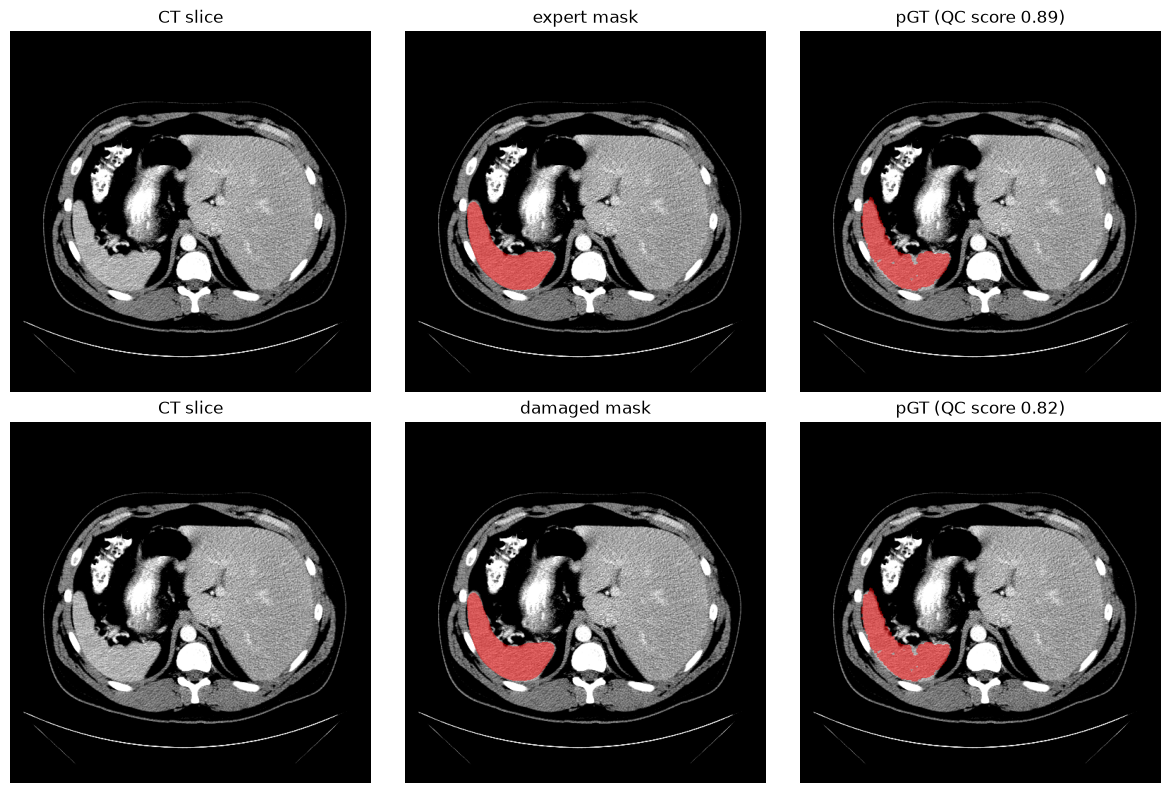

In [10]:
os.makedirs("figures", exist_ok=True)
ct = nib.load(case["image"]).get_fdata()
z = int(np.argmax(expert.sum(axis=(0, 1))))  # slice where the expert mask is largest
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for row, (name, path) in enumerate(candidates.items()):
    pgt_path = os.path.join(work_dir, f"pgt_{row}.nii.gz")
    results[name].save(pgt_path)
    panels = [
        ("CT slice", None),
        (name, nib.load(path).get_fdata()),
        (f"pGT (QC score {results[name].qc_score:.2f})", nib.load(pgt_path).get_fdata()),
    ]
    for col, (title, mask) in enumerate(panels):
        ax = axes[row, col]
        ax.imshow(ct[:, :, z].T, cmap="gray", vmin=-57, vmax=164, origin="lower")  # nnQC's CT window
        if mask is not None:
            ax.imshow(np.ma.masked_equal(mask[:, :, z].T, 0), cmap="autumn", alpha=0.5, origin="lower")
        ax.set_title(title)
        ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join("figures", "part1_released_model_pgt.png"), dpi=100, bbox_inches="tight")
plt.show()

 Besides one grade per patient, nnQC also gives one grade per slice. 



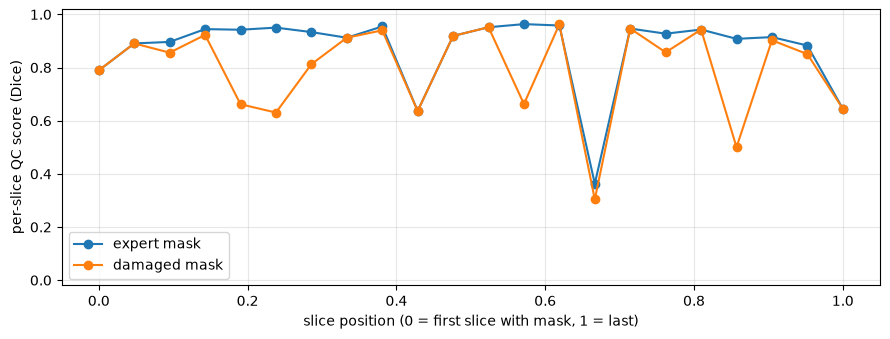

In [11]:
fig, ax = plt.subplots(figsize=(9, 3.5))
for name, result in results.items():
    ax.plot(result.slice_ratios, result.slice_scores, "o-", label=name)
ax.set_xlabel("slice position (0 = first slice with mask, 1 = last)")
ax.set_ylabel("per-slice QC score (Dice)")
ax.set_ylim(-0.02, 1.02)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join("figures", "part1_per_slice_scores.png"), dpi=100, bbox_inches="tight")
plt.show()



## Part 2: train a small nnQC



| Setting | Preset | Here |
|---|---|---|
| Slice size | 256 x 256 | 128 x 128 |
| Batch size (slices per step) | 32 | 16 |
| Autoencoder epochs (validation every) | 500 (10) | 50 (5) |
| Diffusion epochs (validation every) | 7000 (10) | 150 (10) |
| Learning-rate warm-up (diffusion) | 20 epochs | 5 epochs |
| Dice-loss warm-up (diffusion) | 100 epochs | 25 epochs |

Everything else comes from the preset: network sizes, learning rates, losses, the range of corruption severities, and the EMA of the UNet weights.

In [12]:
patch_size = [128, 128]
batch_size = 16
ae_max_epochs = 50
ae_val_interval = 5
diffusion_max_epochs = 150
diffusion_warmup_epochs = 5
diffusion_warmup_dice_epochs = 25

In [13]:
spacing_file = os.path.join(root_dir, "spacing.txt")
if not os.path.isfile(spacing_file):
    labels_dir = os.path.join(root_dir, "Task09_Spleen", "labelsTr")
    label_names = sorted(name for name in os.listdir(labels_dir) if name.startswith("spleen_"))
    spacings = []
    for name in label_names:
        label = nib.as_closest_canonical(nib.load(os.path.join(labels_dir, name)))  # reoriented to RAS
        spacings.append(label.header.get_zooms()[:3])
    median_spacing = tuple(np.median(spacings, axis=0))
    with open(spacing_file, "w") as f:
        f.write(f"{median_spacing[0]} {median_spacing[1]} {median_spacing[2]}\n")
with open(spacing_file) as f:
    print(f"{spacing_file}: {f.read().strip()} mm")

./data\spacing.txt: 0.7929689884185791 0.7929689884185791 5.0 mm




### Stage 1: the autoencoder



In [14]:
%%time
nnqc.train_autoencoder(
    task="spleen",
    data_dir=root_dir,
    patch_size=patch_size,
    batch_size=batch_size,
    epochs=ae_max_epochs,
    val_interval=ae_val_interval,
)

[nnqc] autoencoder | device=0 ddp=False world_size=1
Spacing file already exists: ./data\spacing.txt
Loaded spacing: (0.7929689884185791, 0.7929689884185791, 5.0)
2026-11-08 20:01:14,148 - INFO - Verified 'Task09_Spleen.tar', md5: 410d4a301da4e5b2f6f86ec3ddba524e.
2026-11-08 20:01:14,150 - INFO - File exists: data\Task09_Spleen.tar, skipped downloading.
2026-11-08 20:01:14,151 - INFO - Non-empty folder exists in data\Task09_Spleen, skipped extracting.


Loading dataset: 100%|██████████| 33/33 [00:20<00:00,  1.57it/s]


2026-11-08 20:01:39,213 - INFO - Verified 'Task09_Spleen.tar', md5: 410d4a301da4e5b2f6f86ec3ddba524e.
2026-11-08 20:01:39,214 - INFO - File exists: data\Task09_Spleen.tar, skipped downloading.
2026-11-08 20:01:39,215 - INFO - Non-empty folder exists in data\Task09_Spleen, skipped extracting.


Loading dataset: 100%|██████████| 8/8 [00:06<00:00,  1.16it/s]


TRAIN: Image shape torch.Size([1, 128, 128]), Label shape torch.Size([1, 128, 128])
VAL: Image shape torch.Size([1, 128, 128]), Label shape torch.Size([1, 128, 128])

[nnqc] reconstruction loss: dice_ce

[nnqc] start training autoencoder...


<project_dir>\.venv\Lib\site-packages\torchvision\models\_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
<project_dir>\.venv\Lib\site-packages\torchvision\models\_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=SqueezeNet1_1_Weights.IMAGENET1K_V1`. You can also use `weights=SqueezeNet1_1_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Epoch 0 val_loss: 0.5910812 [============================= ]
Got best val recon loss; saved to ./trained_weights/spleen\autoencoder.pt
Epoch 5 val_loss: 0.0751794 [============================= ]
Got best val recon loss; saved to ./trained_weights/spleen\autoencoder.pt
Epoch 10 val_loss: 0.0521602 [============================= ]
Got best val recon loss; saved to ./trained_weights/spleen\autoencoder.pt
Epoch 15 val_loss: 0.0380385 [============================= ]
Got best val recon loss; saved to ./trained_weights/spleen\autoencoder.pt
Epoch 20 val_loss: 0.0350344 [============================= ]
Got best val recon loss; saved to ./trained_weights/spleen\autoencoder.pt
Epoch 25 val_loss: 0.0307243 [============================= ]
Got best val recon loss; saved to ./trained_weights/spleen\autoencoder.pt
Epoch 30 val_loss: 0.0248211 [============================= ]
Got best val recon loss; saved to ./trained_weights/spleen\autoencoder.pt
Epoch 35 val_loss: 0.0568425 [====================

'./trained_weights/spleen'



### Stage 2: diffusion UNet



In [15]:
%%time
nnqc.train_diffusion(
    task="spleen",
    data_dir=root_dir,
    patch_size=patch_size,
    batch_size=batch_size,
    epochs=diffusion_max_epochs,
    warmup_epochs=diffusion_warmup_epochs,
    warmup_dice_epochs=diffusion_warmup_dice_epochs,
)

[nnqc] diffusion | device=0 ddp=False world_size=1
Spacing file already exists: ./data\spacing.txt
Loaded spacing: (0.7929689884185791, 0.7929689884185791, 5.0)
[nnqc] diffusion loader: batch_size=16 patch_size=[128, 128]
2026-11-08 20:18:12,619 - INFO - Verified 'Task09_Spleen.tar', md5: 410d4a301da4e5b2f6f86ec3ddba524e.
2026-11-08 20:18:12,620 - INFO - File exists: data\Task09_Spleen.tar, skipped downloading.
2026-11-08 20:18:12,621 - INFO - Non-empty folder exists in data\Task09_Spleen, skipped extracting.


Loading dataset: 100%|██████████| 33/33 [00:18<00:00,  1.83it/s]


2026-11-08 20:18:34,078 - INFO - Verified 'Task09_Spleen.tar', md5: 410d4a301da4e5b2f6f86ec3ddba524e.
2026-11-08 20:18:34,080 - INFO - File exists: data\Task09_Spleen.tar, skipped downloading.
2026-11-08 20:18:34,080 - INFO - Non-empty folder exists in data\Task09_Spleen, skipped extracting.


Loading dataset: 100%|██████████| 8/8 [00:09<00:00,  1.13s/it]


TRAIN: Image shape torch.Size([1, 128, 128]), Label shape torch.Size([1, 128, 128])
VAL: Image shape torch.Size([1, 128, 128]), Label shape torch.Size([1, 128, 128])

Rank 0: loaded autoencoder from ./trained_weights/spleen\autoencoder.pt
Latent feature shape torch.Size([16, 2, 32, 32])
Rank 0: scale_factor -> 0.6578


Loading weights: 100%|██████████| 197/197 [00:00<00:00, 15152.17it/s]
[transformers] BertModel LOAD REPORT from: microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
bert.pooler.dense.bias                     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be

[nnqc] corruption severity scale ~ U(0.0, 6.0)
[nnqc] best checkpoint selected on: recon
Epoch 0 val -> EMA 0.9998 | raw 1.0016852, recon 0.0000 [============================= ]
Got best val (recon=0.99981); saved to ./trained_weights/spleen\diffusion_unet.pt
Epoch 10 val -> EMA 0.9614 | raw 0.5887765, recon 0.0000 [============================= ]
Got best val (recon=0.96136); saved to ./trained_weights/spleen\diffusion_unet.pt
Epoch 20 val -> EMA 0.8232 | raw 0.3058767, recon 0.0000 [============================= ]
Got best val (recon=0.82322); saved to ./trained_weights/spleen\diffusion_unet.pt
32/33 epoch 24, total 0.2161, noise 0.2161, recon 0.0000 [============================= ]
[nnqc] warmup done; enabling decoded-mask Dice loss.

Epoch 30 val -> EMA 0.6707 | raw 0.2267294, recon 0.0175 [============================= ]
Got best val (recon=0.04393); saved to ./trained_weights/spleen\diffusion_unet.pt
Epoch 40 val -> EMA 0.4864 | raw 0.1983704, recon 0.0195 [======================

'./trained_weights/spleen'


## Part 3: evaluate the small model






### Training curves



autoencoder.pt: val_recon_loss = 0.0231
diffusion_unet.pt: val_diffusion_loss_2 = 0.0189


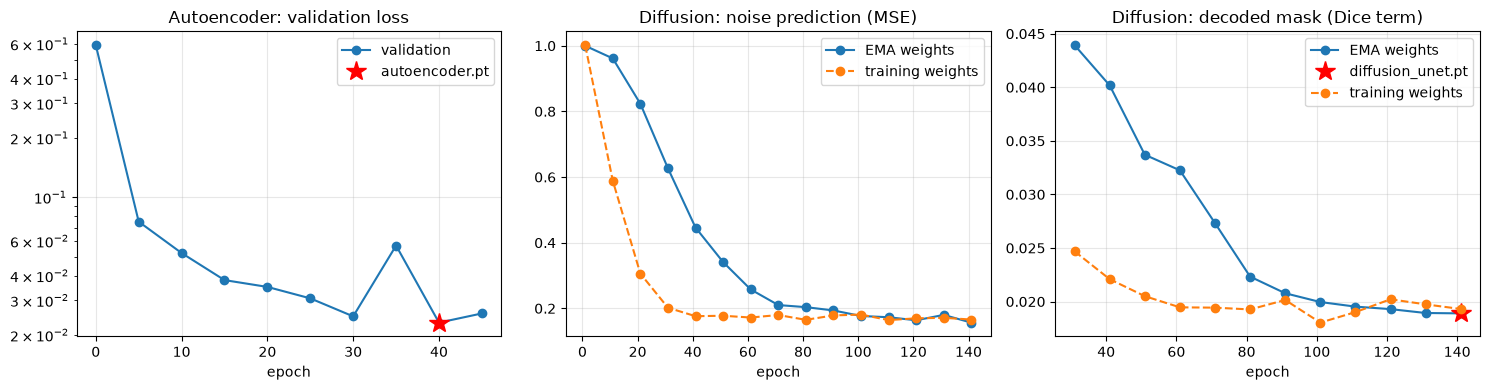

In [14]:
log_root = "./tfevent/spleen"  # the spleen preset's tfevent_path
logs = {}
for stage in ["autoencoder", "diffusion"]:
    log_files = glob.glob(os.path.join(log_root, stage, "events.out.tfevents.*"))
    logs[stage] = EventAccumulator(max(log_files, key=os.path.getmtime)).Reload()  # most recent run

panels = {
    "Autoencoder: validation loss": [("autoencoder", "val_recon_loss", "validation")],
    "Diffusion: noise prediction (MSE)": [
        ("diffusion", "val_diffusion_loss_1", "EMA weights"),
        ("diffusion", "val_diffusion_loss_1_raw", "training weights"),
    ],
    "Diffusion: decoded mask (Dice term)": [
        ("diffusion", "val_diffusion_loss_2", "EMA weights"),
        ("diffusion", "val_diffusion_loss_2_raw", "training weights"),
    ],
}
kept = {"val_recon_loss": "autoencoder.pt", "val_diffusion_loss_2": "diffusion_unet.pt"}  # selected on these

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (title, series) in zip(axes, panels.items()):
    for stage, tag, label in series:
        events = logs[stage].Scalars(tag)
        epochs = np.array([event.step for event in events])
        values = np.array([event.value for event in events])
        ax.plot(epochs, values, "o--" if label == "training weights" else "o-", label=label)
        if tag in kept:
            best = int(np.argmin(values))
            ax.plot(epochs[best], values[best], "r*", markersize=15, label=kept[tag])
            print(f"{kept[tag]}: {tag} = {values[best]:.4f}")
    ax.set_title(title)
    ax.set_xlabel("epoch")
    ax.grid(alpha=0.3)
    ax.legend()
axes[0].set_yscale("log")
plt.tight_layout()
plt.savefig(os.path.join("figures", "part3_training_curves.png"), dpi=100, bbox_inches="tight")
plt.show()

In [15]:
set_determinism(seed=0)  # the candidates do not depend on what ran before
severities = [0.0, 2.0, 4.0, 6.0]  # the spleen preset's diffusion_train.val_severities
sweep_dir = os.path.join(work_dir, "part3")
os.makedirs(sweep_dir, exist_ok=True)

sweep = []  # one entry per candidate
for val_case in val_files:
    patient = os.path.basename(val_case["label"]).replace(".nii.gz", "")
    gt_nii = nib.load(val_case["label"])
    gt = np.asarray(gt_nii.dataobj).astype(np.float32)  # [H, W, slices]
    gt_slices = torch.from_numpy(gt).permute(2, 0, 1).unsqueeze(1)  # [slices, 1, H, W]
    for severity in severities:
        candidate = corrupt_ohe_masks_v2(gt_slices, corruption_prob=1.0, config=scaled_config(severity))
        candidate = candidate[:, 0].permute(1, 2, 0).numpy()
        path = os.path.join(sweep_dir, f"{patient}_severity{severity:g}.nii.gz")
        nib.save(nib.Nifti1Image(candidate, gt_nii.affine), path)
        sweep.append(
            {
                "patient": patient,
                "image": val_case["image"],
                "severity": severity,
                "candidate": path,
                "true Dice": dice(candidate, gt),
            }
        )

print(f"{len(sweep)} candidates in {sweep_dir}")
for severity in severities:
    true_dices = [entry["true Dice"] for entry in sweep if entry["severity"] == severity]
    print(f"severity {severity:g}: true Dice from {min(true_dices):.3f} to {max(true_dices):.3f}")

32 candidates in ./data\nnqc_work\part3
severity 0: true Dice from 1.000 to 1.000
severity 2: true Dice from 0.596 to 0.699
severity 4: true Dice from 0.230 to 0.445
severity 6: true Dice from 0.128 to 0.231


In [16]:
%%time
small_model_dir = "./trained_weights/spleen"  # the spleen preset's model_dir, where Part 2 saved our model
models = {
    "released model": {"model_dir": model_dir},  # downloaded in Part 1, 256 x 256 slices
    "our small model": {"model_dir": small_model_dir, "patch_size": patch_size},  # Part 2, 128 x 128 slices
}
for name, settings in models.items():
    for entry in sweep:
        with contextlib.redirect_stdout(io.StringIO()):  # hide check's three printed lines
            result = nnqc.check(
                entry["image"], entry["candidate"], task="spleen", auto_download=False, return_volume=False, **settings
            )
        entry[name] = result.qc_score

CPU times: total: 19min 56s
Wall time: 13min 19s


severity  true Dice   released model  our small model  (means over 8 patients)
       0      1.000            0.909            0.638
       2      0.652            0.656            0.500
       4      0.312            0.321            0.294
       6      0.173            0.180            0.182
released model: Pearson r = 0.994, Spearman rho = 0.985, MAE = 0.039
our small model: Pearson r = 0.973, Spearman rho = 0.964, MAE = 0.148


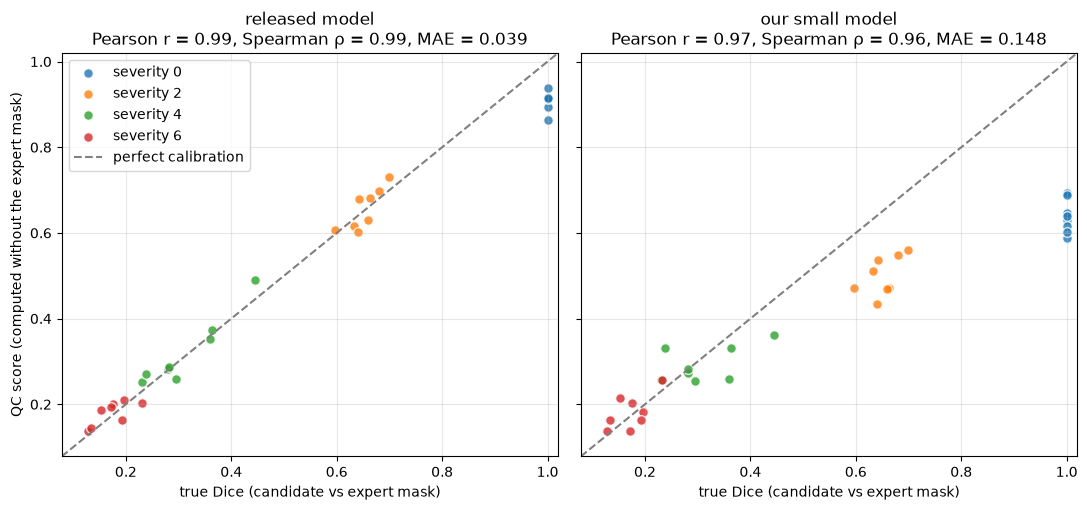

In [17]:
true_dice = np.array([entry["true Dice"] for entry in sweep])
levels = np.array([entry["severity"] for entry in sweep])
scores = {name: np.array([entry[name] for entry in sweep]) for name in models}
low = min(true_dice.min(), *(qc.min() for qc in scores.values())) - 0.05

print(f"{'severity':>8}{'true Dice':>11}" + "".join(f"{name:>17}" for name in models) + "  (means over 8 patients)")
for severity in severities:
    row = f"{severity:>8g}{true_dice[levels == severity].mean():>11.3f}"
    print(row + "".join(f"{scores[name][levels == severity].mean():>17.3f}" for name in models))

fig, axes = plt.subplots(1, 2, figsize=(11, 5.2), sharex=True, sharey=True)
for ax, (name, qc) in zip(axes, scores.items()):
    pearson = pearsonr(qc, true_dice).statistic
    spearman = spearmanr(qc, true_dice).statistic
    mae = np.mean(np.abs(qc - true_dice))
    print(f"{name}: Pearson r = {pearson:.3f}, Spearman rho = {spearman:.3f}, MAE = {mae:.3f}")
    for severity in severities:
        chosen = levels == severity
        ax.scatter(true_dice[chosen], qc[chosen], s=48, alpha=0.8, edgecolor="white", label=f"severity {severity:g}")
    ax.plot([low, 1.02], [low, 1.02], "--", color="0.5", label="perfect calibration")
    ax.set_title(f"{name}\nPearson r = {pearson:.2f}, Spearman ρ = {spearman:.2f}, MAE = {mae:.3f}")
    ax.set_xlabel("true Dice (candidate vs expert mask)")
    ax.set_xlim(low, 1.02)
    ax.set_ylim(low, 1.02)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("QC score (computed without the expert mask)")
axes[0].legend(loc="upper left")
plt.tight_layout()
plt.savefig(os.path.join("figures", "part3_qc_vs_true_dice.png"), dpi=100, bbox_inches="tight")
plt.show()